# 07. Развёртка фазы, остатки и несвязанные области

Курс «От интерференции до измерения поверхности». [Маршрут](README.md).

**Цели:** вывести условие локальной однозначности, выполнить обход по качеству и увидеть границы восстановления.

Работайте сверху вниз, затем меняйте параметры и выполняйте **Restart Kernel → Run All**.
Все численные примеры учебные: они объясняют метод, а не подтверждают точность прибора.
Рекомендуемый темп: одна тетрадь за занятие, с собственными записями и упражнениями.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, signal, interpolate, optimize

course_dir = next(p for p in [Path.cwd(), Path.cwd()/"notes"/"interferometry-course"]
                  if (p/"course_lib.py").exists())
if str(course_dir) not in sys.path:
    sys.path.insert(0, str(course_dir))
import course_lib as cl
np.set_printoptions(precision=5, suppress=True)

## 1. Что именно потерял atan2

Комплексное поле задаёт $w=\operatorname{Arg}(e^{i\varphi})\in(-\pi,\pi]$.
Искомая фаза $\varphi=w+2\pi k$, где k — неизвестное целое для каждой точки.
Развёртка ищет согласованные k, пользуясь пространственной непрерывностью.

Для пары соседних точек, если **истинное** приращение удовлетворяет
$|\varphi_{j+1}-\varphi_j|<\pi$, то оно равно wrap(wⱼ₊₁−wⱼ).
Отсюда одномерный алгоритм:
$$u_{j+1}=u_j+\operatorname{wrap}(w_{j+1}-w_j).$$
Это условие на истинное поле, а не проверка по уже свёрнутым отсчётам.

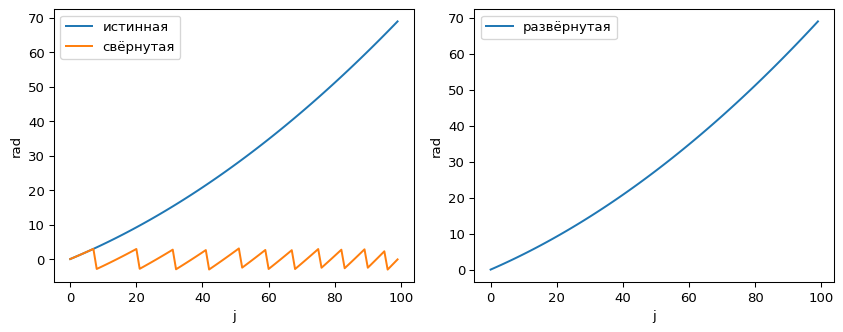

In [2]:
x=np.arange(100)
truth=.4*x+.003*x*x
wrapped=cl.wrap(truth)
unwrapped=np.unwrap(wrapped)
assert np.max(np.abs((unwrapped-truth)-(unwrapped-truth).mean()))<1e-10
fig,axes=plt.subplots(1,2)
axes[0].plot(x,truth,label='истинная'); axes[0].plot(x,wrapped,label='свёрнутая'); axes[0].legend()
axes[1].plot(x,unwrapped,label='развёрнутая'); axes[1].legend()
for ax in axes: ax.set(xlabel='j',ylabel='rad')
plt.tight_layout(); plt.show()

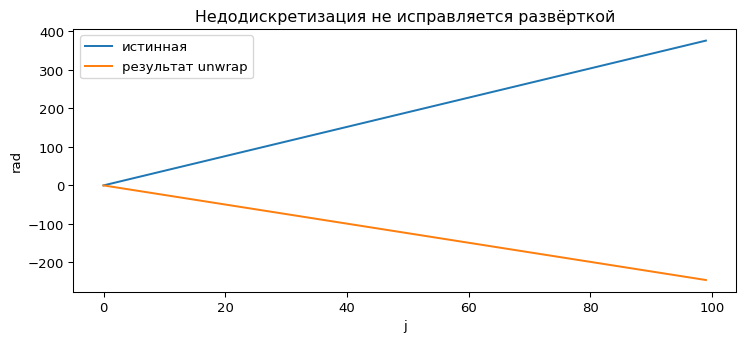

Наблюдаемый наклон: -2.4831853071795886 вместо 3.8


In [3]:
truth_fast=3.8*x  # больше π на один пиксель
wrong=np.unwrap(cl.wrap(truth_fast))
plt.plot(x,truth_fast,label='истинная'); plt.plot(x,wrong,label='результат unwrap')
plt.legend(); plt.xlabel('j'); plt.ylabel('rad'); plt.title('Недодискретизация не исправляется развёрткой'); plt.show()
print('Наблюдаемый наклон:',np.polyfit(x,wrong,1)[0],'вместо 3.8')

## 2. В 2D появляется выбор пути

Обход строками, BFS и обход по качеству интегрируют локальные приращения по разным
путям. Без шума, при выполнении условия выше и на связной области они согласуются
с истинной фазой с точностью до общей константы 2πk.

В обходе по качеству ребро между точками можно оценивать минимумом их надёжностей.
Очередь с приоритетом сначала проводит восстановление по хорошим участкам.
Надёжность часто связана с амплитудой комплексного поля или оценкой дисперсии фазы.
Модуляция b/a — удобная эвристика, но не универсальный эквивалент отношения сигнал/шум.

{'rms': 0.004002087883547021, 'pv': 0.027904385408023202, 'bias': 1.0000923222164206, 'coverage': 1.0} компонент: 1


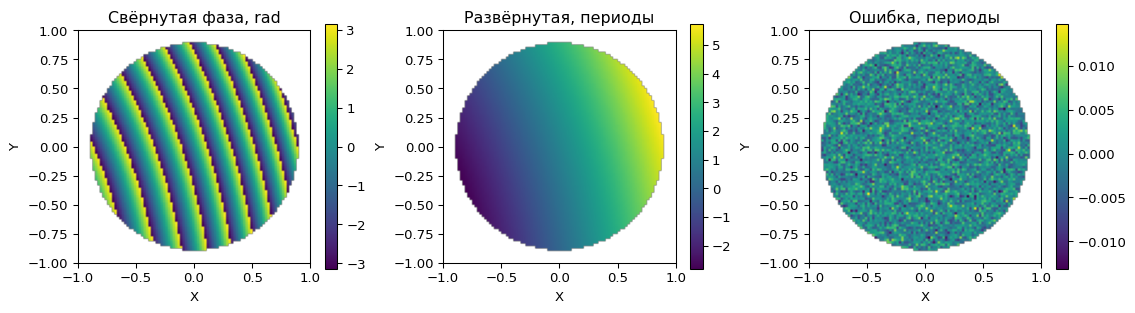

In [4]:
s=cl.scene(n=96,carrier_x=9,carrier_y=3,bowl=.5)
quality=np.ones((96,96))
quality[:,45:51]=.03
noise=np.random.default_rng(11).normal(0,.025,s['phi'].shape)
wrapped=cl.wrap(s['phi']+noise)
restored,labels=cl.unwrap_quality(wrapped,quality,s['mask'])
error,stats=cl.compare(restored/cl.TAU,s['orders'],s['mask'])
print(stats,'компонент:',labels.max())
cl.show_maps([wrapped,restored/cl.TAU,error],['Свёрнутая фаза, rad','Развёрнутая, периоды','Ошибка, периоды'],s['mask'])

## 3. Невязка по замкнутому контуру

Обойдём четыре стороны пиксельной ячейки и сложим свёрнутые приращения.
Сумма должна быть 0 для совместимых локальных данных. Значение ±2π —
фазовый остаток (residue), указывающий на конфликт локальной развёртки.
Он может возникать из-за шума, разрыва или сингулярности комплексного поля.

Обход по дереву не проверяет все циклы и может перенести ошибку на большую область.
Другие классы методов используют разрезы, минимизацию невязки градиентов,
сети потоков или регуляризацию. Решение Пуассона по шумным градиентам может
сгладить ошибку, но не обязано точно сохранять исходные свёрнутые значения.

Ячеек с ненулевым остатком: 567


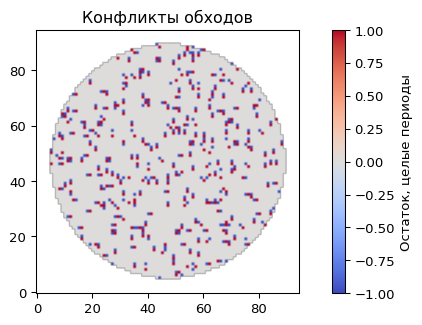

In [5]:
noisy=cl.wrap(s['phi']+np.random.default_rng(9).normal(0,1.0,s['phi'].shape))
charge=(cl.wrap(noisy[:-1,1:]-noisy[:-1,:-1])+
        cl.wrap(noisy[1:,1:]-noisy[:-1,1:])+
        cl.wrap(noisy[1:,:-1]-noisy[1:,1:])+
        cl.wrap(noisy[:-1,:-1]-noisy[1:,:-1]))/cl.TAU
cells=s['mask'][:-1,:-1]&s['mask'][1:,:-1]&s['mask'][:-1,1:]&s['mask'][1:,1:]
print('Ячеек с ненулевым остатком:',np.sum(np.abs(charge[cells])>.5))
plt.imshow(np.where(cells,np.rint(charge),np.nan),origin='lower',cmap='coolwarm',vmin=-1,vmax=1)
plt.colorbar(label='Остаток, целые периоды'); plt.title('Конфликты обходов'); plt.show()

## 4. Между островками остаётся неизвестный порядок

Если убрать полосу пикселей и разорвать апертуру на две части, каждая часть имеет
собственный неопределённый k. Восстановление по каждой компоненте **не определяет**
их взаимную высоту. Добавление 2π к одному островку никак не меняет исходные данные.

Для согласования нужны дополнительные сведения: непрерывная промежуточная область,
многочастотные измерения, физическая модель или известное перемещение.
Слепая полиномиальная подгонка всех островков может превратить неизвестный порядок
в ложную аберрацию.

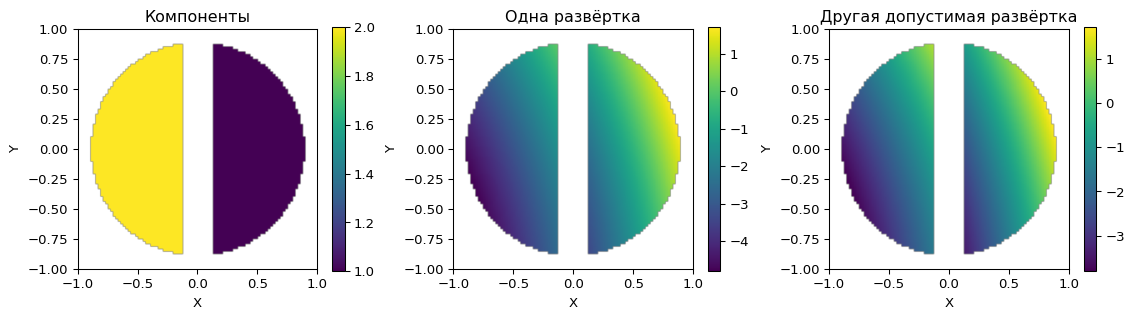

In [6]:
split=s['mask']&(np.abs(s['x'])>.12)
restored,labels=cl.unwrap_quality(cl.wrap(s['phi']),np.ones(split.shape),split)
assert labels.max()==2
alternative=restored.copy(); alternative[labels==2]+=cl.TAU
assert np.allclose(np.exp(1j*restored[split]),np.exp(1j*alternative[split]))
cl.show_maps([labels,restored/cl.TAU,alternative/cl.TAU],['Компоненты','Одна развёртка','Другая допустимая развёртка'],split)

## Задания

1. Почему по величине wrap(Δφ) нельзя узнать, нарушено ли условие |Δφ_true|<π?
2. Прибавьте 10 периодов только второй компоненте. Изменится ли комплексное поле?
3. Сравните при сильном шуме построчную развёртку и обход по качеству.
4. Почему маленький RMS остатка полиномов не определяет правильный порядок между островками?

<details><summary>Разбор</summary>

Свёртка по определению всегда возвращает малое значение: большие приращения уже
потеряны. Целое число периодов не меняет exp(iφ). Разные пути могут распространять
ошибки по-разному. Полиномы подгоняют уже выбранные ветви, не создавая новых измерений.
</details>

**Чтение:** [Itoh, 1982](https://opg.optica.org/ao/abstract.cfm?uri=ao-21-14-2470).
**В проекте:** `PhaseUnwrapping.cpp` хранит число компонент; не следует воспринимать
несколько независимо развёрнутых областей как автоматически сшитый единый фронт.
Далее: [PSI с известными сдвигами](08_psi_known.ipynb).